In [26]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer, KNNImputer, MissingIndicator

In [27]:
df = pd.read_csv(r"C:\Users\chamu\Documents\Modelx\Dementia Prediction Dataset.csv")

C:\Users\chamu\AppData\Local\Temp\ipykernel_8912\2638997370.py:1: DtypeWarning: Columns (20,22,24,26,28,41,44,46,48,51,61,63,65,67,69,71,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,105,106,107,108,109,110,111,112,113,114,134,156,165,176,179,189,217,220,222,224,226,228,230,232,234,236,238,240,242,244,246,248,250,252,254,256,258,260,262,264,266,268,270,272,382,397,399,401,419,421,423,432,445,454,494,574,605,613,638,674,690,704,707,710,715,727,738,744,746,803,804,809,810,811,812,820,831,833,835,837,843,904,959,960,961,969,970,971,972,982,1004,1007,1010) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(r"C:\Users\chamu\Documents\Modelx\Dementia Prediction Dataset.csv")


In [ ]:
non_medical_variable_list = [
    "NACCAGE",
    "SEX",
    "HISPANIC",
    "RACE",
    "EDUC",
    "MARISTAT",
    "NACCLIVS",aaaa
    "INDEPEND",
    "RESIDENC",
    "HANDED",
    "INRELTO",
    "INLIVWTH",
    "INVISITS",
    "INCALLS",
    "TOBAC30",
    "TOBAC100",
    "SMOKYRS",
    "PACKSPER",
    "QUITSMOK",
    "ALCOCCAS",
    "ALCFREQ",
    # "PRIMLANG",
    # "PRIMLANX"
]

# Step 2: your non-medical features
features_to_keep = [col for col in non_medical_variable_list if col in df.columns]

# Step 3: Add target BEFORE filtering
features_to_keep.append("DEMENTED")

# Step 4: Filter
df = df[features_to_keep]



df

,NACCAGE,SEX,HISPANIC,RACE,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,HANDED,...,INVISITS,INCALLS,TOBAC30,TOBAC100,SMOKYRS,PACKSPER,QUITSMOK,ALCOCCAS,ALCFREQ,DEMENTED
0,70,1,0,1,16,1,4,1,1,2,...,8,8,0,0,0,0,888,1,2,0
1,71,1,0,1,16,1,2,1,1,2,...,8,8,-4,-4,-4,-4,-4,-4,-4,0
2,66,1,0,1,16,1,2,1,1,2,...,8,8,0,0,0,0,888,1,4,0
3,63,2,1,1,16,1,2,2,1,2,...,-4,-4,0,0,0,0,888,0,8,1
4,77,1,1,1,12,3,1,1,1,2,...,4,1,0,0,0,0,888,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195191,72,2,0,2,13,4,4,2,9,2,...,3,1,0,0,0,0,888,-4,-4,1
195192,87,1,0,1,13,2,1,1,1,2,...,3,2,0,1,40,2,60,-4,-4,0
195193,89,1,0,1,13,2,1,3,2,2,...,3,2,0,1,40,2,60,-4,-4,1
195194,89,1,0,1,13,2,1,3,2,2,...,3,3,0,1,40,2,60,-4,-4,1


In [29]:
missing_codes = [-4, -5, 88, 888, 8888, 999, 9999]
df.replace(missing_codes, np.nan, inplace=True)

df

,NACCAGE,SEX,HISPANIC,RACE,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,HANDED,...,INVISITS,INCALLS,TOBAC30,TOBAC100,SMOKYRS,PACKSPER,QUITSMOK,ALCOCCAS,ALCFREQ,DEMENTED
0,70.0,1,0,1,16,1,4,1,1,2,...,8.0,8.0,0.0,0.0,0.0,0.0,NaN,1.0,2.0,0
1,71.0,1,0,1,16,1,2,1,1,2,...,8.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,66.0,1,0,1,16,1,2,1,1,2,...,8.0,8.0,0.0,0.0,0.0,0.0,NaN,1.0,4.0,0
3,63.0,2,1,1,16,1,2,2,1,2,...,NaN,NaN,0.0,0.0,0.0,0.0,NaN,0.0,8.0,1
4,77.0,1,1,1,12,3,1,1,1,2,...,4.0,1.0,0.0,0.0,0.0,0.0,NaN,1.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195191,72.0,2,0,2,13,4,4,2,9,2,...,3.0,1.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,1
195192,87.0,1,0,1,13,2,1,1,1,2,...,3.0,2.0,0.0,1.0,40.0,2.0,60.0,NaN,NaN,0
195193,89.0,1,0,1,13,2,1,3,2,2,...,3.0,2.0,0.0,1.0,40.0,2.0,60.0,NaN,NaN,1
195194,89.0,1,0,1,13,2,1,3,2,2,...,3.0,3.0,0.0,1.0,40.0,2.0,60.0,NaN,NaN,1


In [30]:
my_imputer = SimpleImputer(strategy = "most_frequent")

In [31]:
#Since theres no objects, i dont need to exclude anything

#numerical_columns = df.select_dtypes(exclude=['object'])
imputed_data = my_imputer.fit_transform(df)
imputed_df = pd.DataFrame(imputed_data, columns=df.columns)
imputed_df.head()

,NACCAGE,SEX,HISPANIC,RACE,EDUC,MARISTAT,NACCLIVS,INDEPEND,RESIDENC,HANDED,...,INVISITS,INCALLS,TOBAC30,TOBAC100,SMOKYRS,PACKSPER,QUITSMOK,ALCOCCAS,ALCFREQ,DEMENTED
0,70.0,1.0,0.0,1.0,16.0,1.0,4.0,1.0,1.0,2.0,...,8.0,8.0,0.0,0.0,0.0,0.0,40.0,1.0,2.0,0.0
1,71.0,1.0,0.0,1.0,16.0,1.0,2.0,1.0,1.0,2.0,...,8.0,8.0,0.0,0.0,0.0,0.0,40.0,1.0,8.0,0.0
2,66.0,1.0,0.0,1.0,16.0,1.0,2.0,1.0,1.0,2.0,...,8.0,8.0,0.0,0.0,0.0,0.0,40.0,1.0,4.0,0.0
3,63.0,2.0,1.0,1.0,16.0,1.0,2.0,2.0,1.0,2.0,...,8.0,8.0,0.0,0.0,0.0,0.0,40.0,0.0,8.0,1.0
4,77.0,1.0,1.0,1.0,12.0,3.0,1.0,1.0,1.0,2.0,...,4.0,1.0,0.0,0.0,0.0,0.0,40.0,1.0,0.0,0.0


In [32]:
imputed_df.columns.tolist()

['NACCAGE',
 'SEX',
 'HISPANIC',
 'RACE',
 'EDUC',
 'MARISTAT',
 'NACCLIVS',
 'INDEPEND',
 'RESIDENC',
 'HANDED',
 'INRELTO',
 'INLIVWTH',
 'INVISITS',
 'INCALLS',
 'TOBAC30',
 'TOBAC100',
 'SMOKYRS',
 'PACKSPER',
 'QUITSMOK',
 'ALCOCCAS',
 'ALCFREQ',
 'DEMENTED']

In [33]:
X = imputed_df[non_medical_variable_list]
Y = imputed_df["DEMENTED"]

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()


In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify=Y)

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [36]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['liblinear', 'saga'],
    'max_iter': [1000, 2500]
}

grid = GridSearchCV(
    LogisticRegression(class_weight='balanced'),
    param_grid,
    scoring='f1',  # or 'recall'
    cv=5
)


grid.fit(X_train_scaled, y_train)
model = grid.best_estimator_


In [37]:
model

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'liblinear'
,max_iter,1000
,multi_class,'deprecated'


In [44]:

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay


In [45]:
classification_report(y_test, y_pred)

NameError: name 'y_pred' is not defined

In [ ]:
from sklearn.metrics import f1_score
f1_score(y_test, y_pred)


In [ ]:
import numpy as np
from sklearn.metrics import f1_score


#Calculating the threshold

thresholds = np.arange(0.0, 1.01, 0.01)
f1_scores = []

y_scores = model.predict_proba(X_test_scaled)[:, 1]

for t in thresholds:
    preds = (y_scores >= t).astype(int)
    f1_scores.append(f1_score(y_test, preds))

# Find the best threshold
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print("Best Threshold:", best_threshold)
print("Best F1 Score:", best_f1)

# Plot
import matplotlib.pyplot as plt

plt.plot(thresholds, f1_scores)
plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("F1 Score vs Threshold")
plt.grid(True)
plt.show()

In [ ]:
# model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

# predict on test set
# y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test_scaled)[:, 1]

custom_threshold = best_threshold
y_pred = (y_prob >= custom_threshold).astype(int)
print("Accuracy: ", accuracy_score(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)


In [ ]:
import matplotlib.pyplot as plt

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap=plt.cm.Blues)

plt.title("Confusion Matrix")
plt.show()

In [ ]:
#custom testing data

new_person = [[75, 1, 0, 1, 16, 2, 1, 1, 1, 1,   # A1
               1, 1, 2, 2,                      # A2
               1, 1, 25, 1.0, 55, 1, 2,         # A5
               # If you removed the 5 CLS columns, do not include them
              ]]


In [ ]:
def predict_dementia_risk(model, scaler, input_row, threshold=None):
    input_scaled = scaler.transform([input_row])
    proba = model.predict_proba(input_scaled)[0][1]  # Probability of class 1

    if threshold is not None:
        return "At Risk" if proba >= threshold else "Not At Risk"
    else:
        return round(proba * 100, 2)


label = predict_dementia_risk(model, scaler, new_person[0], threshold=best_threshold)
print(f"Prediction: {label}")



In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)


accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = f1_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred)

In [ ]:
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))
print("ROC-AUC  :", round(roc_auc, 4))


In [ ]:
#######################--------------MLPClassifier-----------###################################

In [ ]:
scaler = StandardScaler();
# X_train_scaled = scaler.fit_transform(X_train)

from sklearn.neural_network import MLPClassifier

In [ ]:
model_nn = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver='adam',
    max_iter=500,
    random_state=42
)

model_nn.fit(X_train_scaled, y_train)

y_pred_nn = model_nn.predict(X_test_scaled)
y_proba_nn = model_nn.predict_proba(X_test_scaled)[:, 1] 

print("Neural Network Performance: ")
print(classification_report(y_test, y_pred_nn))

roc_auc = roc_auc_score(y_test, y_proba_nn)
print(f"ROC-AUC Score: {roc_auc:.2f}")


In [ ]:

thresholds = np.arange(0.0, 1.01, 0.01)
f1_scores = []

for t in thresholds:
    preds = (y_proba_nn >= t).astype(int)
    f1_scores.append(f1_score(y_test, preds))

# Best threshold
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print(f"Best Threshold: {best_threshold:.2f}")
print(f"Best F1 Score: {best_f1:.4f}")


In [ ]:
# Use the best threshold to make new predictions
custom_preds = (y_proba_nn >= best_threshold).astype(int)
custom_preds

In [ ]:
cm_nn = confusion_matrix(y_test, custom_preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_nn, display_labels=model_nn.classes_)
disp.plot(cmap=plt.cm.Blues)

plt.title("Confusion Matrix")
plt.show()

In [ ]:
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba_nn):.2f}")

In [40]:
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay


In [ ]:
#######################--------------DecisionTree-----------###################################

Decision Tree Performance:
Accuracy : 0.8673
Precision: 0.7836
Recall   : 0.7599
F1 Score : 0.7716
ROC-AUC  : 0.8407

Classification Report:
              precision    recall  f1-score   support

         0.0       0.90      0.91      0.91     27522
         1.0       0.78      0.76      0.77     11518

    accuracy                           0.87     39040
   macro avg       0.84      0.84      0.84     39040
weighted avg       0.87      0.87      0.87     39040



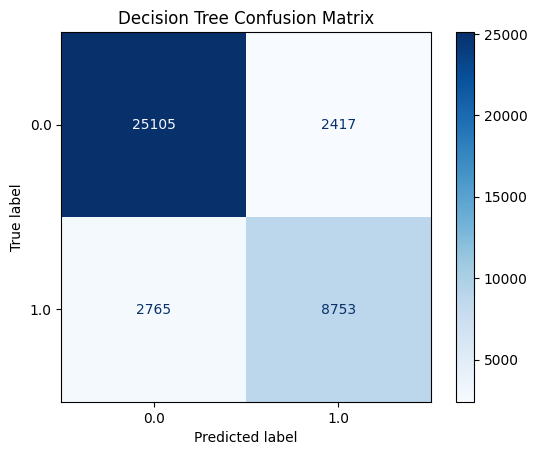

Best Threshold: 0.41
Best F1 Score: 0.7729


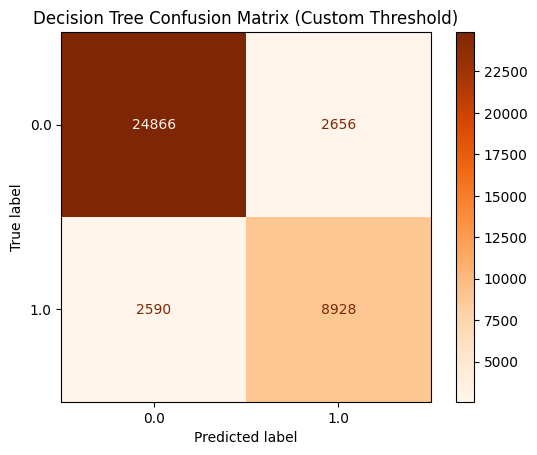

In [41]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

# Initialize Decision Tree
model_dt = DecisionTreeClassifier(
    max_depth=None,  # You can set this to avoid overfitting
    random_state=42
)

# Fit the model
model_dt.fit(X_train_scaled, y_train)

# Predict
y_pred_dt = model_dt.predict(X_test_scaled)
y_proba_dt = model_dt.predict_proba(X_test_scaled)[:, 1]  # Probability for ROC-AUC

# Performance metrics
accuracy = accuracy_score(y_test, y_pred_dt)
precision = precision_score(y_test, y_pred_dt)
recall = recall_score(y_test, y_pred_dt)
f1 = f1_score(y_test, y_pred_dt)
roc_auc = roc_auc_score(y_test, y_proba_dt)

print("Decision Tree Performance:")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

# Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=model_dt.classes_)
disp.plot(cmap=plt.cm.Blues)
plt.title("Decision Tree Confusion Matrix")
plt.show()

# Optional: Find best threshold for F1 (similar to neural network)
thresholds = np.arange(0.0, 1.01, 0.01)
f1_scores = []

for t in thresholds:
    preds = (y_proba_dt >= t).astype(int)
    f1_scores.append(f1_score(y_test, preds))

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]
best_f1 = f1_scores[best_index]

print(f"Best Threshold: {best_threshold:.2f}")
print(f"Best F1 Score: {best_f1:.4f}")

# Use best threshold for custom predictions
custom_preds_dt = (y_proba_dt >= best_threshold).astype(int)
cm_custom_dt = confusion_matrix(y_test, custom_preds_dt)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_custom_dt, display_labels=model_dt.classes_)
disp.plot(cmap=plt.cm.Oranges)
plt.title("Decision Tree Confusion Matrix (Custom Threshold)")
plt.show()
